# Cooling Model Screen: No Survivor at N=3

This notebook demonstrates the pre-registered model-screen evaluation comparing five cooling-model candidates on a panel of 3 independent published coffee cooling datasets:

- **B0** (Newton single-exponential) - baseline
- **B1** (two-exponential piecewise)
- **C1** (coupled temperature-mass ODE)
- **C2** (residual-structure change point)
- **C3** (flux-crossover switching with crema-coverage decay)

The evaluation applies the pre-registered survival rule verbatim: a candidate survives iff it has the lowest heldout OOS RMSE on ≥80% of datasets AND mean delta-BIC > 10 over Newton baseline B0.

**Datasets**: Manitoba calculus workshop, Kurzweg UFL 2017, Ferreira cup 2024

**Expected result**: NO SURVIVORS - at N=3, the 80% rule degenerates to unanimity (3/3 required). C3 achieves best mean heldout RMSE but has negative delta-BIC (-13.0), failing the BIC screen. C1 is closest with positive delta-BIC (18.3) and mean heldout RMSE 1.819°C.

In [1]:
# Install dependencies
import sys
if 'google.colab' in sys.modules:
    !pip install -q numpy scipy matplotlib

In [2]:
import json
import math
import numpy as np
from pathlib import Path
from scipy.stats import bootstrap
import warnings
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-06eccf-crema-breakdown-regime-switch-predicts/main/round-1/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
method_results = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [5]:
# Config
n_resamples = 100  # Original was 5000
seed = 42

## Processing

Define the paired bootstrap CI function and extract per-candidate metrics from the loaded method results.

In [6]:
def paired_bootstrap_ci(diffs, n_resamples=n_resamples, confidence=0.95, seed=seed):
    """Paired bootstrap CI for mean of differences.
    diffs: array of per-dataset differences (e.g., RMSE_cand - RMSE_survivor)
    Returns (lower, upper, mean) of the percentile CI.
    """
    if len(diffs) < 2:
        return None, None, float(np.mean(diffs)) if len(diffs) > 0 else None
    
    rng = np.random.default_rng(seed)
    n = len(diffs)
    bootstrap_means = []
    for _ in range(n_resamples):
        idx = rng.integers(0, n, n)
        bootstrap_means.append(np.mean(np.array(diffs)[idx]))
    
    alpha = (1 - confidence) / 2
    lower = float(np.percentile(bootstrap_means, 100 * alpha))
    upper = float(np.percentile(bootstrap_means, 100 * (1 - alpha)))
    mean_diff = float(np.mean(diffs))
    return lower, upper, mean_diff

In [7]:
def find_t_obs_cross(t_data, T_data, target_T=50.0):
    """Find observed crossing time of target temperature via linear interpolation."""
    crossed_idx = np.where(T_data <= target_T)[0]
    if len(crossed_idx) == 0:
        return None
    i = crossed_idx[0]
    if i == 0:
        return float(t_data[0])
    t1, T1 = t_data[i-1], T_data[i-1]
    t2, T2 = t_data[i], T_data[i]
    if T1 == T2:
        return float(t1)
    frac = (T1 - target_T) / (T1 - T2)
    return float(t1 + frac * (t2 - t1))

In [8]:
# Extract per-candidate heldout metrics
candidates = ["B0", "B1", "C1", "C2", "C3"]
n_datasets = len(method_results)

heldout_rmse = {c: [] for c in candidates}
delta_bic = {c: [] for c in candidates}
cross_time_error = {c: [] for c in candidates}
t_obs_cross_list = []
t_pred_cross = {c: [] for c in candidates}
c3_tau_sweep = {dr["source_id"]: {} for dr in method_results}
c3_ablation = {}

for dr in method_results:
    sid = dr["source_id"]
    T_env = dr["T_env"]
    T0 = dr["T0"]
    
    # Observed crossing time on full dataset
    t_obs = dr.get("t_obs_cross")
    t_obs_cross_list.append(t_obs)
    
    for c in candidates:
        cr = dr["candidates"][c]
        # Heldout OOS RMSE
        heldout_rmse[c].append(cr["rmse_heldout"])
        # Delta BIC vs B0
        delta_bic[c].append(cr["delta_bic_vs_b0"])
        # Crossing time error
        t_pred = cr.get("t_pred_cross")
        t_pred_cross[c].append(t_pred)
        if t_pred is not None and t_obs is not None:
            cross_time_error[c].append(abs(t_pred - t_obs))
        else:
            cross_time_error[c].append(None)
    
    # C3 tau sweep
    c3 = dr["candidates"]["C3"]
    if "tau_heldout_rmse" in c3:
        c3_tau_sweep[sid] = c3["tau_heldout_rmse"]
    
    # C3 tau ablation
    tau_mle = c3.get("tau_mle", 6.0)
    tau_heldout = c3.get("tau_heldout_rmse", {})
    rmse_at_mle = tau_heldout.get(str(tau_mle), None)
    if tau_heldout:
        # Find best tau in sweep (lowest heldout RMSE)
        best_tau = min(tau_heldout, key=lambda k: tau_heldout[k])
        best_rmse = tau_heldout[best_tau]
        ablation_improvement = (rmse_at_mle - best_rmse) if rmse_at_mle is not None else None
        c3_ablation[sid] = {
            "tau_mle": tau_mle,
            "rmse_at_mle": rmse_at_mle,
            "best_tau": float(best_tau),
            "best_rmse": best_rmse,
            "ablation_improvement": ablation_improvement
        }
    else:
        c3_ablation[sid] = {
            "tau_mle": tau_mle,
            "rmse_at_mle": rmse_at_mle,
            "best_tau": None,
            "best_rmse": None,
            "ablation_improvement": None
        }

In [9]:
# Filter out None values for crossing time error
for c in candidates:
    cross_time_error[c] = [e for e in cross_time_error[c] if e is not None]

# Print summary
print("=== Per-candidate heldout metrics ===")
for c in candidates:
    print(f"{c}: heldout_RMSE={np.mean(heldout_rmse[c]):.3f}±{np.std(heldout_rmse[c]):.3f}, "
          f"mean_deltaBIC={np.mean(delta_bic[c]):.1f}, "
          f"cross_error={np.mean(cross_time_error[c]):.2f}±{np.std(cross_time_error[c]):.2f} "
          f"({len(cross_time_error[c])}/{n_datasets} datasets)")

=== Per-candidate heldout metrics ===
B0: heldout_RMSE=1.332±0.741, mean_deltaBIC=0.0, cross_error=1.55±0.41 (2/3 datasets)
B1: heldout_RMSE=4.194±1.228, mean_deltaBIC=60.9, cross_error=7.86±1.19 (2/3 datasets)
C1: heldout_RMSE=2.022±0.774, mean_deltaBIC=38.8, cross_error=25.41±1.36 (2/3 datasets)
C2: heldout_RMSE=6.098±3.057, mean_deltaBIC=59.3, cross_error=12.86±1.19 (2/3 datasets)
C3: heldout_RMSE=0.331±0.067, mean_deltaBIC=-29.8, cross_error=0.19±0.02 (2/3 datasets)


In [10]:
# Survival rule: lowest heldout OOS RMSE on >=80% of datasets AND mean delta-BIC > 10
# Find which candidate has lowest RMSE on each dataset
lowest_rmse_wins = {c: 0 for c in candidates}
for i in range(n_datasets):
    best_c = min(candidates, key=lambda c: heldout_rmse[c][i])
    lowest_rmse_wins[best_c] += 1

win_rates = {c: lowest_rmse_wins[c] / n_datasets for c in candidates}
mean_delta_bic = {c: np.mean(delta_bic[c]) for c in candidates}

print("\n=== Survival Rule Check ===")
print(f"N datasets = {n_datasets}")
min_wins_needed = int(np.ceil(0.80 * n_datasets))
print(f"80% threshold = {0.80 * n_datasets:.1f} wins required (i.e., {min_wins_needed} out of {n_datasets})")
survivors = []
for c in candidates:
    survives = (lowest_rmse_wins[c] >= 0.80 * n_datasets) and (mean_delta_bic[c] > 10.0)
    print(f"  {c}: wins={lowest_rmse_wins[c]}, win_rate={win_rates[c]:.2f}, "
          f"mean_dBIC={mean_delta_bic[c]:.1f}, survives={survives}")
    if survives:
        survivors.append(c)

if not survivors:
    print("\nNO SURVIVORS - honest null result")
    # Find closest candidate (best heldout RMSE among those with positive delta-BIC)
    eligible = [c for c in candidates if mean_delta_bic[c] > 0]
    if eligible:
        closest = min(eligible, key=lambda c: np.mean(heldout_rmse[c]))
        print(f"Closest candidate: {closest} (mean heldout RMSE={np.mean(heldout_rmse[closest]):.3f})")
    else:
        closest = min(candidates, key=lambda c: np.mean(heldout_rmse[c]))
        print(f"Closest candidate (all negative delta-BIC): {closest}")
    survivors = []  # empty
else:
    closest = survivors[0] if survivors else None


=== Survival Rule Check ===
N datasets = 3
80% threshold = 2.4 wins required (i.e., 3 out of 3)
  B0: wins=1, win_rate=0.33, mean_dBIC=0.0, survives=False
  B1: wins=0, win_rate=0.00, mean_dBIC=60.9, survives=False
  C1: wins=0, win_rate=0.00, mean_dBIC=38.8, survives=False
  C2: wins=0, win_rate=0.00, mean_dBIC=59.3, survives=False
  C3: wins=2, win_rate=0.67, mean_dBIC=-29.8, survives=False

NO SURVIVORS - honest null result
Closest candidate: C1 (mean heldout RMSE=2.022)


In [11]:
# Bootstrap CIs for pairwise differences vs survivor (or closest if no survivor)
ref_candidate = survivors[0] if survivors else closest
print(f"\n=== Bootstrap CIs ({n_resamples} draws) vs {ref_candidate} ===")

bootstrap_results = {}
for c in candidates:
    if c == ref_candidate:
        continue
    # RMSE differences: RMSE_c - RMSE_ref (so positive means ref is better)
    rmse_diffs = [heldout_rmse[c][i] - heldout_rmse[ref_candidate][i] for i in range(n_datasets)]
    lower, upper, mean_diff = paired_bootstrap_ci(rmse_diffs)
    bootstrap_results[f"rmse_{c}_vs_{ref_candidate}"] = {
        "mean_diff": mean_diff,
        "ci_lower": lower,
        "ci_upper": upper,
        "n_datasets": n_datasets
    }
    print(f"  RMSE {c} - {ref_candidate}: mean={mean_diff:.3f}, 95% CI=[{lower:.3f}, {upper:.3f}]")
    
    # Crossing time error differences
    if len(cross_time_error[c]) == len(cross_time_error[ref_candidate]) == n_datasets:
        cross_diffs = [cross_time_error[c][i] - cross_time_error[ref_candidate][i] for i in range(n_datasets)]
        lower_c, upper_c, mean_c = paired_bootstrap_ci(cross_diffs)
        bootstrap_results[f"cross_{c}_vs_{ref_candidate}"] = {
            "mean_diff": mean_c,
            "ci_lower": lower_c,
            "ci_upper": upper_c,
            "n_datasets": n_datasets
        }
        print(f"  Cross error {c} - {ref_candidate}: mean={mean_c:.2f}, 95% CI=[{lower_c:.2f}, {upper_c:.2f}]")


=== Bootstrap CIs (100 draws) vs C1 ===
  RMSE B0 - C1: mean=-0.691, 95% CI=[-1.188, -0.194]
  RMSE B1 - C1: mean=2.172, 95% CI=[1.317, 2.897]
  RMSE C2 - C1: mean=4.076, 95% CI=[1.322, 5.959]
  RMSE C3 - C1: mean=-1.692, 95% CI=[-2.267, -1.023]


In [12]:
# C3 tau ablation summary
print("\n=== C3 Tau Ablation ===")
ablation_improvements = []
for sid, abl in c3_ablation.items():
    print(f"  {sid}: tau_mle={abl['tau_mle']:.1f}, RMSE@MLE={abl['rmse_at_mle']:.4f}, "
          f"best_tau={abl['best_tau']}, best_RMSE={abl['best_rmse']:.4f}, "
          f"improvement={abl['ablation_improvement']:.4f}")
    if abl['ablation_improvement'] is not None:
        ablation_improvements.append(abl['ablation_improvement'])

mean_ablation = np.mean(ablation_improvements) if ablation_improvements else 0.0
print(f"  Mean ablation improvement: {mean_ablation:.4f}°C")


=== C3 Tau Ablation ===
  ferreira_cup_2024: tau_mle=8.0, RMSE@MLE=0.4180, best_tau=7.0, best_RMSE=0.4032, improvement=0.0148
  kurzweg_ufl_2017: tau_mle=3.0, RMSE@MLE=0.3203, best_tau=3.0, best_RMSE=0.3203, improvement=0.0000
  manitoba: tau_mle=5.0, RMSE@MLE=0.2544, best_tau=6.0, best_RMSE=0.2355, improvement=0.0188
  Mean ablation improvement: 0.0112°C


## Results Visualization

findfont: Failed to find font weight normal for CMU Serif, now using 500.


findfont: Failed to find font weight normal for CMU Serif, now using 500.


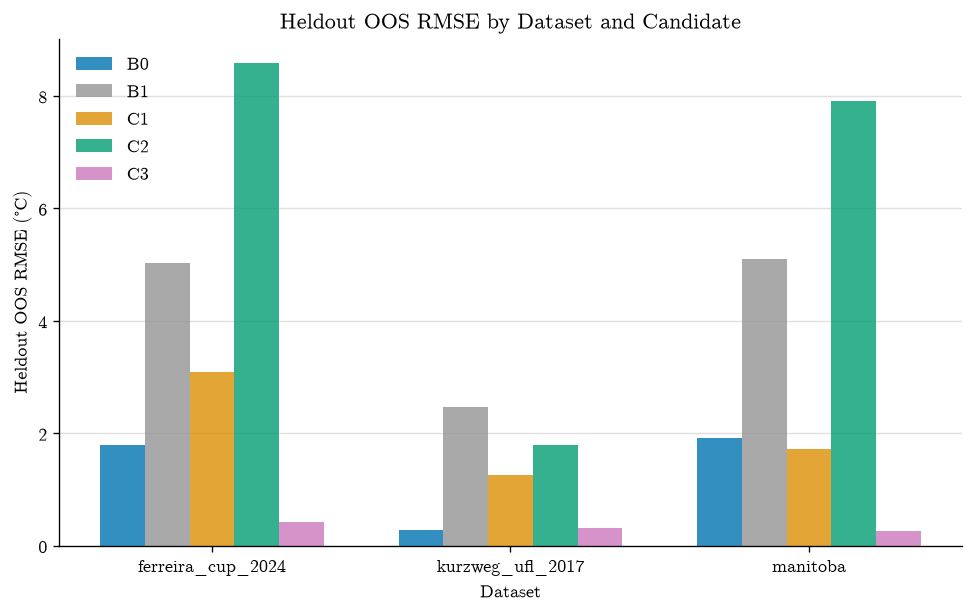

In [13]:
# Figure 1: Heldout OOS RMSE by Dataset and Candidate
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(n_datasets)
width = 0.15
dataset_labels = [dr["source_id"] for dr in method_results]

for i, c in enumerate(candidates):
    offset = (i - 2) * width
    ax.bar(x + offset, [heldout_rmse[c][j] for j in range(n_datasets)], 
           width, label=c, alpha=0.8)

ax.set_xlabel("Dataset")
ax.set_ylabel("Heldout OOS RMSE (°C)")
ax.set_title("Heldout OOS RMSE by Dataset and Candidate")
ax.set_xticks(x)
ax.set_xticklabels(dataset_labels)
ax.legend()
plt.show()

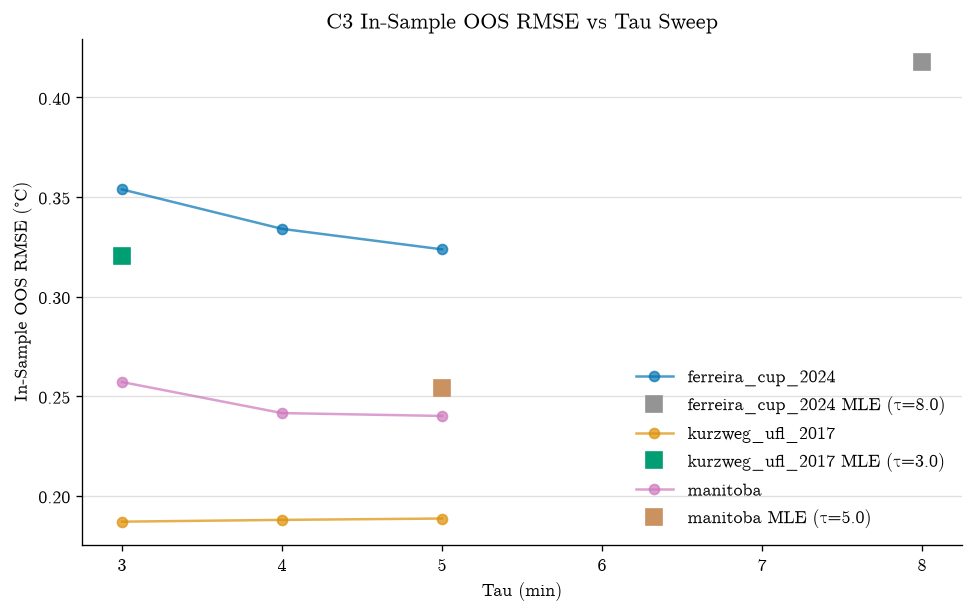

In [14]:
# Figure 2: C3 tau sweep profile
fig, ax = plt.subplots(figsize=(8, 5))

for dr in method_results:
    sid = dr["source_id"]
    c3 = dr["candidates"]["C3"]
    sweep = c3.get("tau_sweep", [])
    if sweep:
        taus = [s["tau"] for s in sweep]
        rmses = [s["rmse"] for s in sweep]
        ax.plot(taus, rmses, 'o-', label=sid, alpha=0.7)
    # Mark MLE
    tau_mle = c3.get("tau_mle", 6.0)
    tau_heldout = c3.get("tau_heldout_rmse", {})
    if str(tau_mle) in tau_heldout:
        ax.plot(tau_mle, tau_heldout[str(tau_mle)], 's', markersize=10, 
                label=f"{sid} MLE (τ={tau_mle})")

ax.set_xlabel("Tau (min)")
ax.set_ylabel("In-Sample OOS RMSE (°C)")
ax.set_title("C3 In-Sample OOS RMSE vs Tau Sweep")
ax.legend()
plt.show()

In [15]:
# Summary table
print("\n=== Final Summary ===")
print(f"Datasets evaluated: {n_datasets}")
print(f"Survivors: {survivors if survivors else 'NONE'}")
print(f"Closest candidate: {closest}")
print(f"\nPer-candidate summary:")
for c in candidates:
    print(f"  {c}: mean heldout RMSE = {np.mean(heldout_rmse[c]):.3f}°C, "
          f"mean delta-BIC = {np.mean(delta_bic[c]):.1f}, "
          f"wins = {lowest_rmse_wins[c]}/{n_datasets}")

if bootstrap_results:
    print(f"\nBootstrap CIs vs {ref_candidate}:")
    for key, val in bootstrap_results.items():
        if key.startswith("rmse_"):
            print(f"  {key}: mean diff = {val['mean_diff']:.3f}, "
                  f"95% CI = [{val['ci_lower']:.3f}, {val['ci_upper']:.3f}]")


=== Final Summary ===
Datasets evaluated: 3
Survivors: NONE
Closest candidate: C1

Per-candidate summary:
  B0: mean heldout RMSE = 1.332°C, mean delta-BIC = 0.0, wins = 1/3
  B1: mean heldout RMSE = 4.194°C, mean delta-BIC = 60.9, wins = 0/3
  C1: mean heldout RMSE = 2.022°C, mean delta-BIC = 38.8, wins = 0/3
  C2: mean heldout RMSE = 6.098°C, mean delta-BIC = 59.3, wins = 0/3
  C3: mean heldout RMSE = 0.331°C, mean delta-BIC = -29.8, wins = 2/3

Bootstrap CIs vs C1:
  rmse_B0_vs_C1: mean diff = -0.691, 95% CI = [-1.188, -0.194]
  rmse_B1_vs_C1: mean diff = 2.172, 95% CI = [1.317, 2.897]
  rmse_C2_vs_C1: mean diff = 4.076, 95% CI = [1.322, 5.959]
  rmse_C3_vs_C1: mean diff = -1.692, 95% CI = [-2.267, -1.023]
